In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chisquare, ks_2samp

Util notebook to plot different densities and compare.


## Plot a single density CSV

In [15]:
EXPERIMENTS_DIR = "experiments"
csv_path = "/Users/gregorioperez/Documents/Maestria/Investigacion/urban_form/edge_importance_ph/filtration_with_importance/experiments/experiment7_usa_eur/europe/average_h1_density.csv"

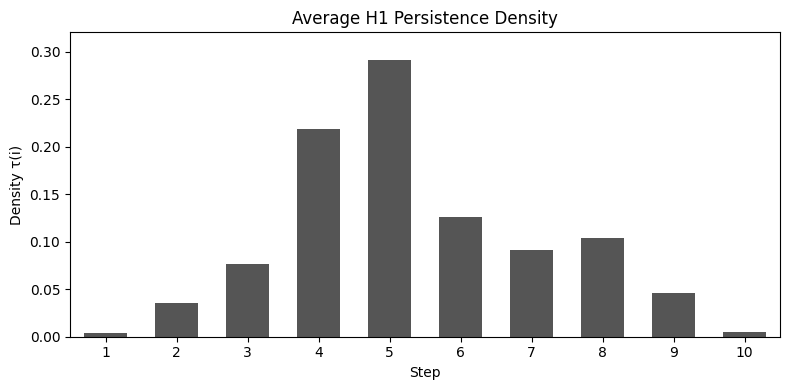

In [16]:
df = pd.read_csv(csv_path)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(df["step"], df["density"], color="#555555", width=0.6)
ax.set_xlim(0.5, df["step"].max() + 0.5)
ax.set_ylim(0, max(df["density"].max() * 1.1, 0.05))
ax.set_xticks(df["step"])
ax.set_xlabel("Step")
ax.set_ylabel("Density τ(i)")
ax.set_title(title)
plt.tight_layout()
plt.show()

## Plot two densities side by side

In [2]:
csv_path_a = EXPERIMENTS_DIR / "experiment7_usa_eur" / "europe" / "average_H1_density.csv"
csv_path_b = EXPERIMENTS_DIR / "experiment7_usa_eur" / "europe" / "average_H1_density.csv"
csv_path_c = EXPERIMENTS_DIR / "experiment7_usa_eur" / "south_america" / "average_H1_density.csv"

label_a = "Eur"
label_b = "Eur"
label_c = "South America"

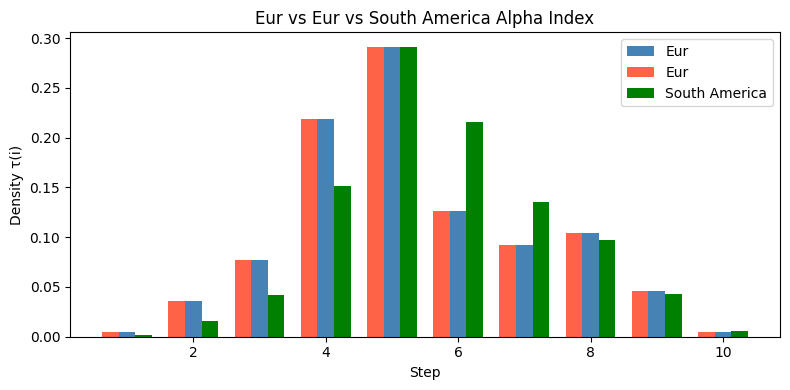

In [3]:
da = pd.read_csv(csv_path_a)
db = pd.read_csv(csv_path_b)
dc = pd.read_csv(csv_path_c)

fig, ax = plt.subplots(figsize=(8, 4))

w = 0.25

ax.bar(
    da["step"] ,
    da["density"],
    width=w,
    label=label_a,
    color="steelblue"
)

ax.bar(
    db["step"] - w,
    db["density"],
    width=w,
    label=label_b,
    color="tomato"
)

ax.bar(
    dc["step"] + w,
    dc["density"],
    width=w,
    label=label_c,
    color="green"
)

ax.set_xlabel("Step")
ax.set_ylabel("Density τ(i)")
ax.set_title(f"{label_a} vs {label_b} vs {label_c} Alpha Index")
ax.legend()

plt.tight_layout()
plt.show()

In [ ]:


csv_path_a = EXPERIMENTS_DIR / "experiment3_usa_eur" / "europe" / "average_H1_density.csv"
csv_path_b = EXPERIMENTS_DIR / "experiment3_usa_eur" / "n_asia" / "average_H1_density.csv"
csv_path_c = EXPERIMENTS_DIR / "experiment3_usa_eur" / "africa" / "average_H1_density.csv"
csv_path_d = EXPERIMENTS_DIR / "experiment3_usa_eur" / "south_america" / "average_H1_density.csv"

label_a = "Europe"
label_b = "North Asia"
label_c = "Africa"
label_d = "South America"

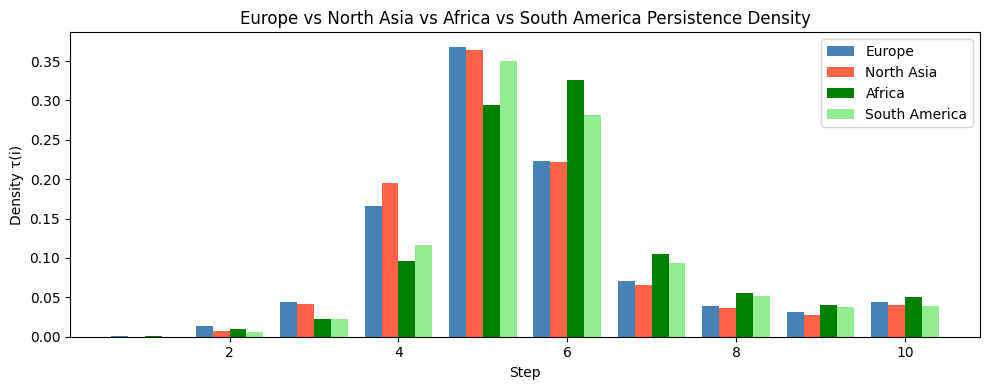

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

da = pd.read_csv(csv_path_a)
db = pd.read_csv(csv_path_b)
dc = pd.read_csv(csv_path_c)
dd = pd.read_csv(csv_path_d)

fig, ax = plt.subplots(figsize=(10, 4))

w = 0.2

ax.bar(
    da["step"] - 1.5 * w,
    da["density"],
    width=w,
    label=label_a,
    color="steelblue"
)

ax.bar(
    db["step"] - 0.5 * w,
    db["density"],
    width=w,
    label=label_b,
    color="tomato"
)

ax.bar(
    dc["step"] + 0.5 * w,
    dc["density"],
    width=w,
    label=label_c,
    color="green"
)

ax.bar(
    dd["step"] + 1.5 * w,
    dd["density"],
    width=w,
    label=label_d,
    color="lightgreen"
)

ax.set_xlabel("Step")
ax.set_ylabel("Density τ(i)")
ax.set_title(
    f"{label_a} vs {label_b} vs {label_c} vs {label_d} Persistence Density"
)
ax.legend()
#ax.set_ylim(0, 0.2)
plt.tight_layout()
plt.show()


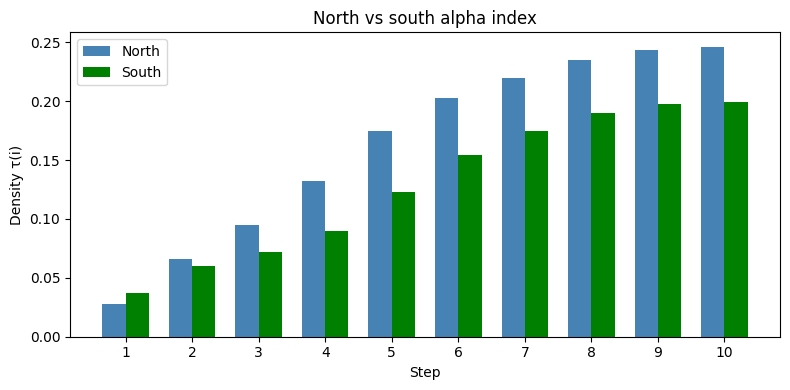

In [14]:
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

base = Path(
    "/Users/gregorioperez/Documents/Maestria/Investigacion/urban_form/"
    "edge_importance_ph/filtration_with_importance/experiments/experiment7_usa_eur"
)

usa = pd.read_csv(base / "usa" / "average_alpha_index.csv")
eur = pd.read_csv(base / "europe" / "average_alpha_index.csv")
s_asia = pd.read_csv(base / "s_asia" / "average_alpha_index.csv")
n_asia = pd.read_csv(base / "n_asia" / "average_alpha_index.csv")
s_america = pd.read_csv(base / "south_america" / "average_alpha_index.csv")
africa = pd.read_csv(base / "africa" / "average_alpha_index.csv")

df = (
    usa.rename(columns={"alpha": "usa"})
    .merge(eur.rename(columns={"alpha": "europe"}), on="step")
    .merge(n_asia.rename(columns={"alpha": "north_asia"}), on="step")
    .merge(s_asia.rename(columns={"alpha": "south_asia"}), on="step")
    .merge(s_america.rename(columns={"alpha": "south_america"}), on="step")
    .merge(africa.rename(columns={"alpha": "africa"}), on="step")
)

df["North"] = df[["usa", "europe", "north_asia"]].mean(axis=1)
df["South"] = df[["south_america", "africa", "south_asia"]].mean(axis=1)
fig, ax = plt.subplots(figsize=(8, 4))

w = 0.35

ax.bar(
    df["step"] - w / 2,
    df["North"],
    width=w,
    label="North",
    color="steelblue",
)

ax.bar(
    df["step"] + w / 2,
    df["South"],
    width=w,
    label="South",
    color="green",
)

ax.set_xlabel("Step")
ax.set_ylabel("Density τ(i)")
ax.set_title("North vs south alpha index")
ax.set_xticks(df["step"])
ax.legend()


plt.tight_layout()
plt.savefig('north_south_alpha.png')
plt.show()


In [5]:
df.head()

,step,usa,europe,north_asia,south_asia,south_america,africa,North,South
0,1,0.000859,0.004284,0.002908,0.004329,0.002139,0.003271,0.002572,0.003246
1,2,0.011991,0.035708,0.028963,0.028858,0.016063,0.016456,0.023850,0.020459
2,3,0.030372,0.076625,0.089132,0.056675,0.042222,0.027460,0.053498,0.042119
3,4,0.108285,0.219143,0.266896,0.147058,0.151801,0.079625,0.163714,0.126161
4,5,0.179430,0.291367,0.352817,0.278254,0.291150,0.184479,0.235399,0.251294


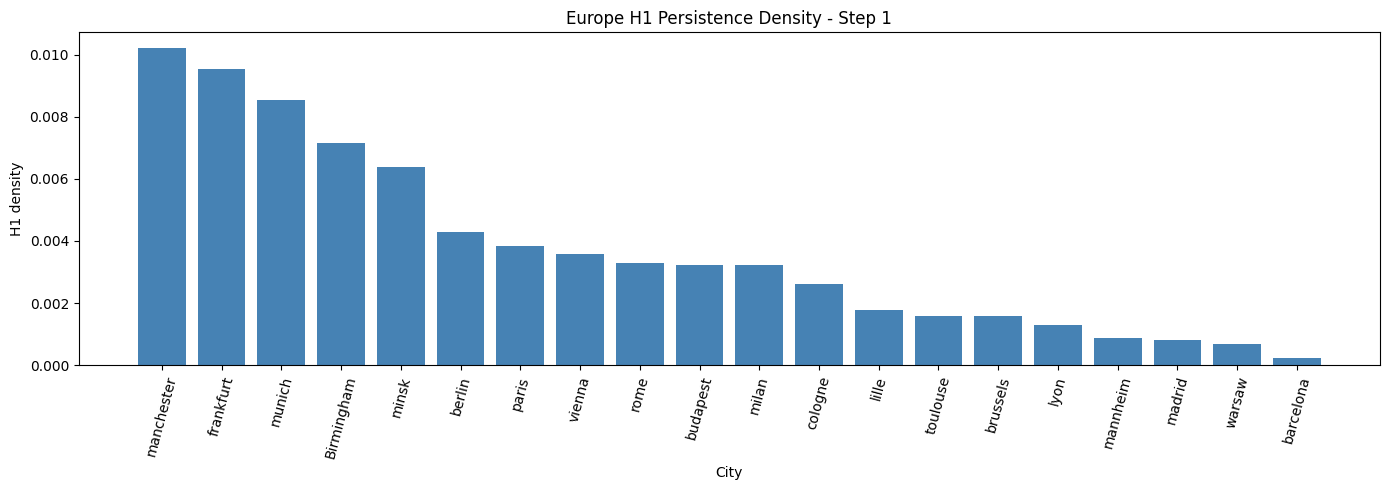

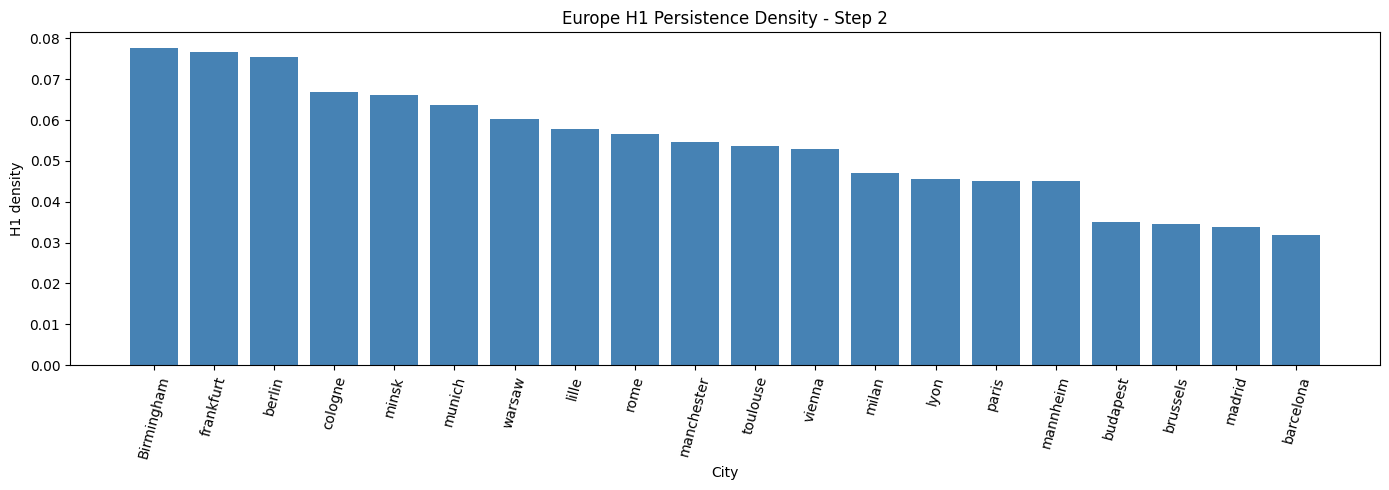

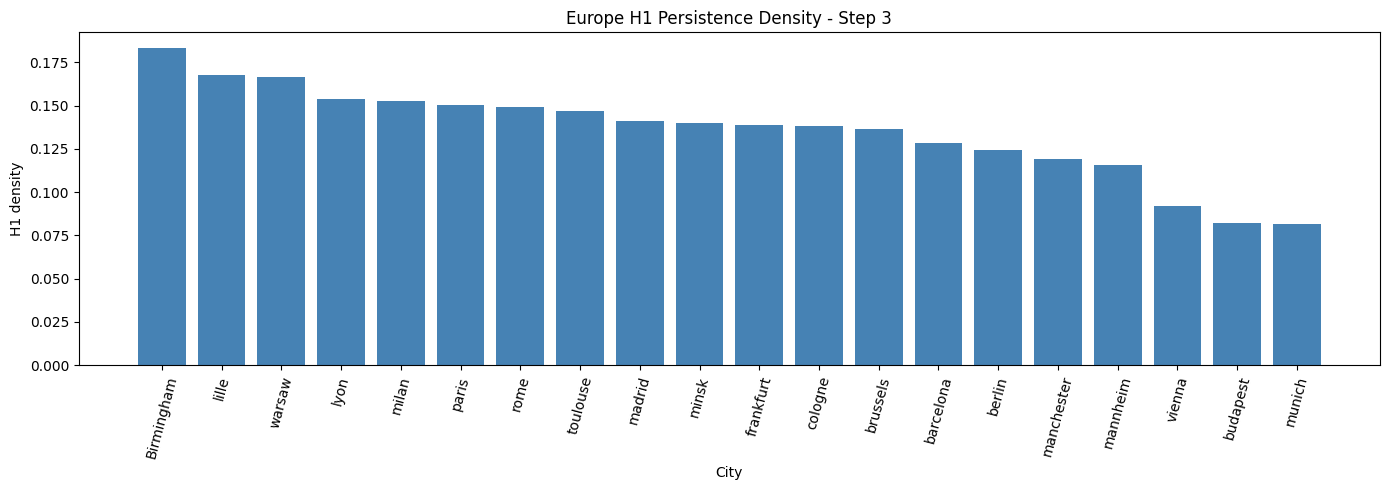

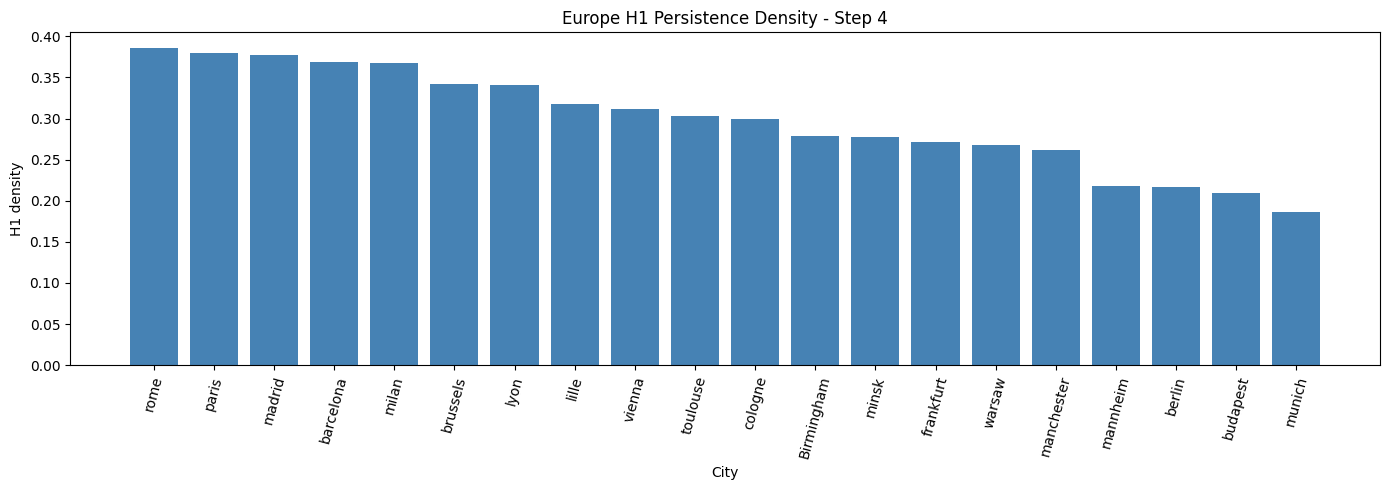

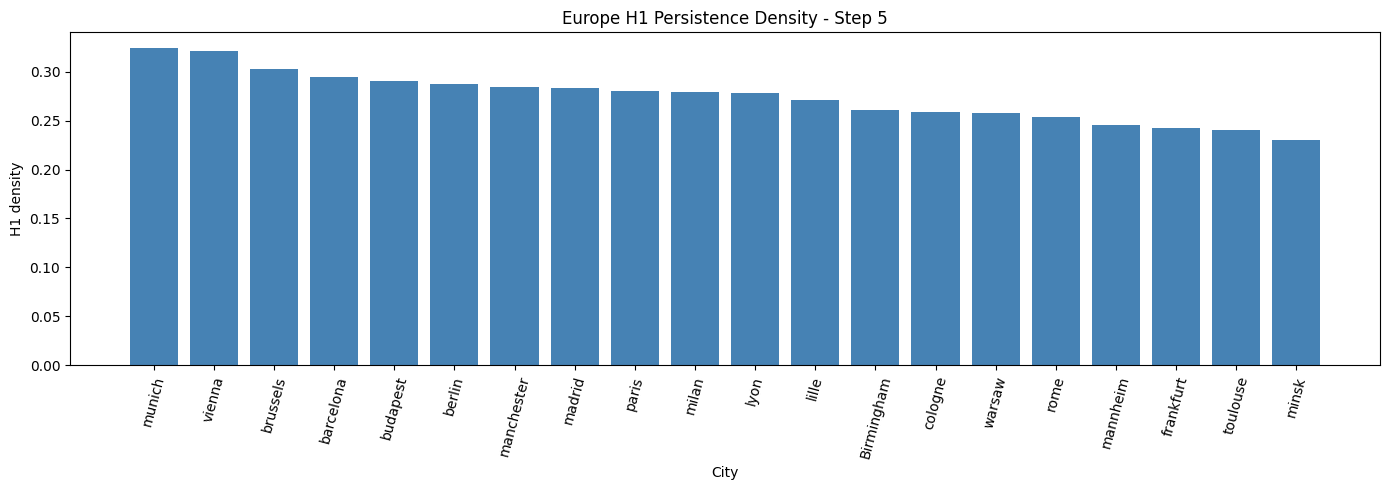

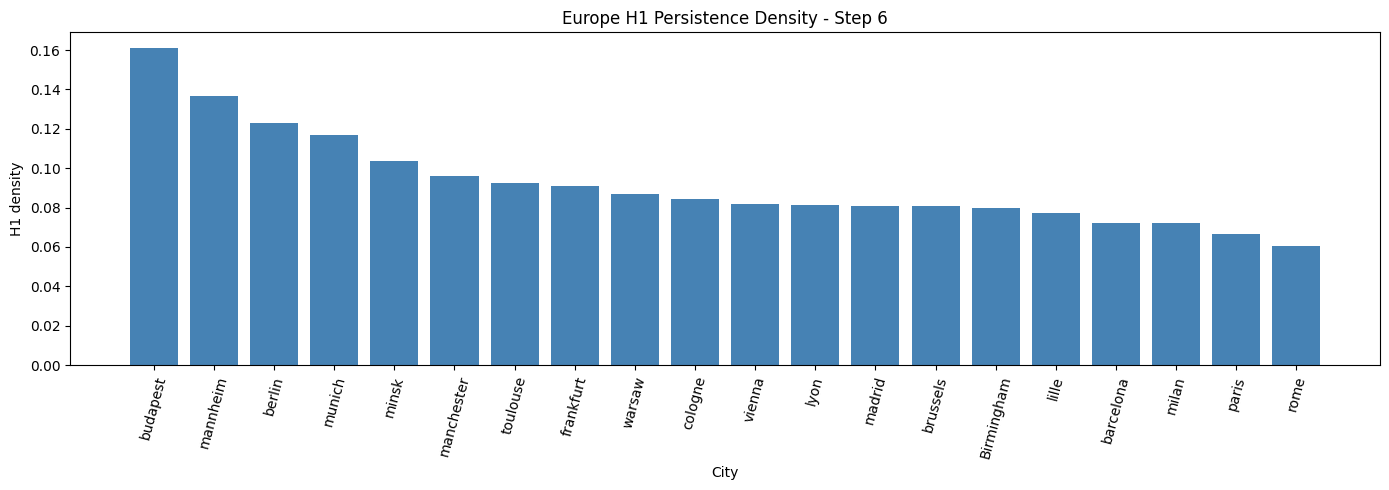

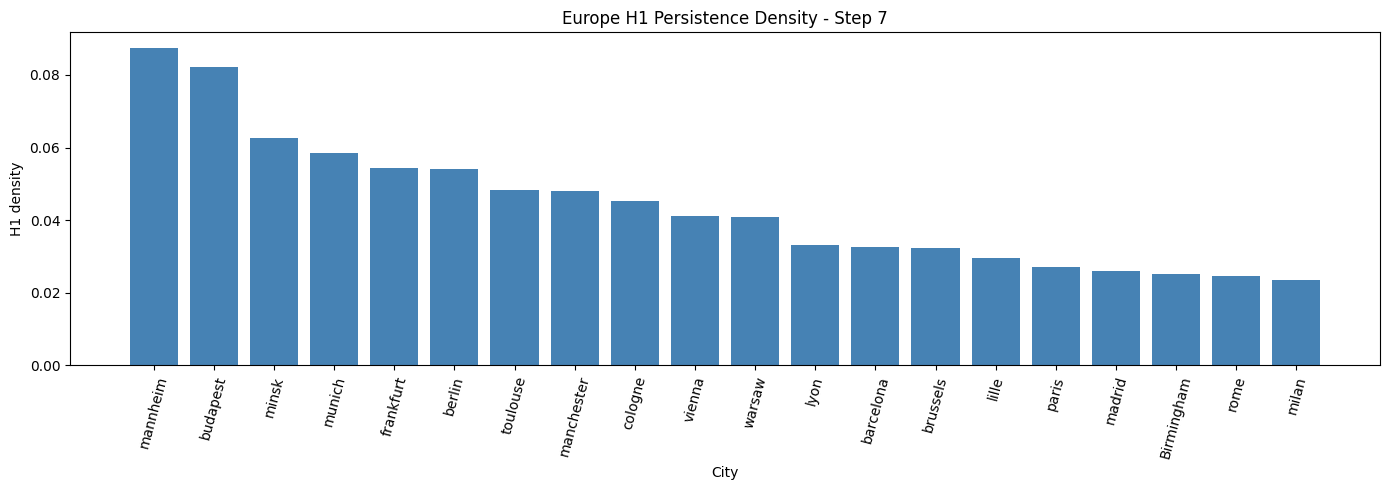

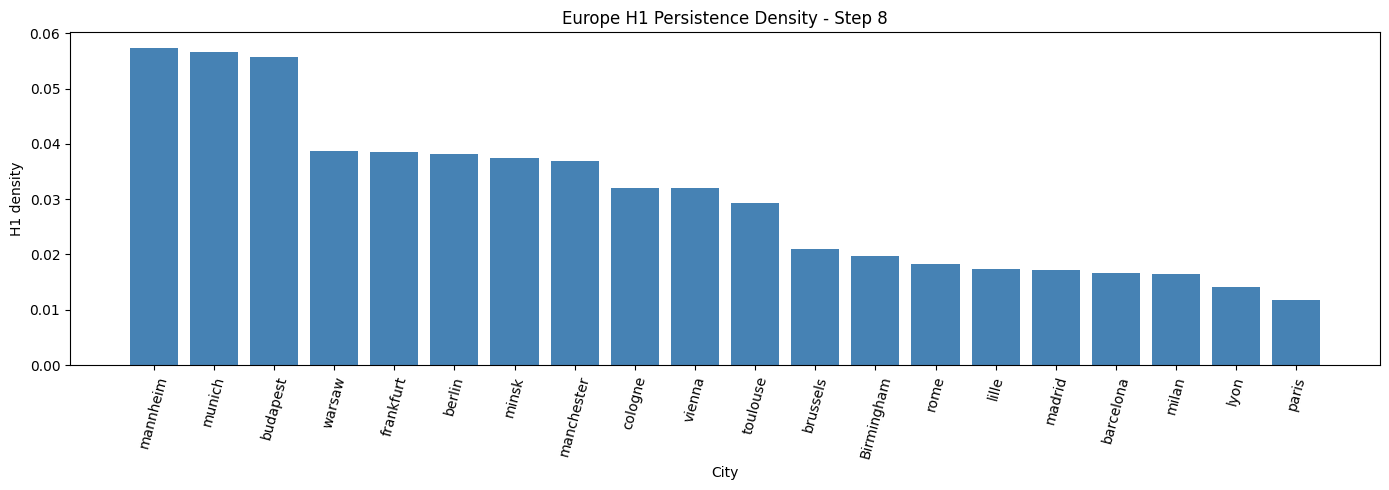

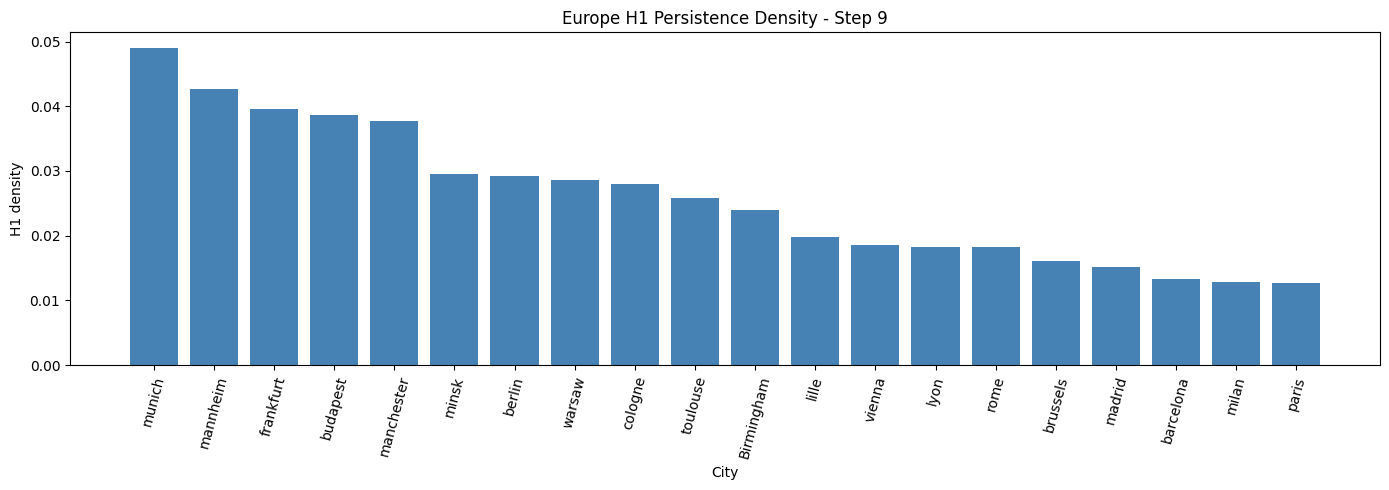

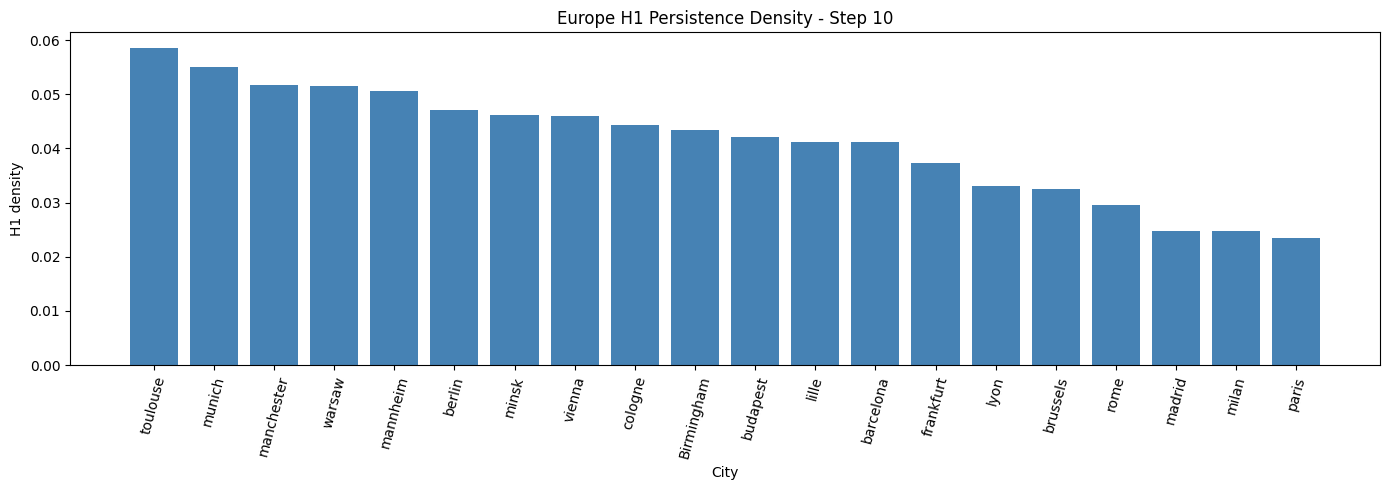

In [ ]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

folder = EXPERIMENTS_DIR / "experiment7_usa_eur" / "europe"

rows = []

for csv_path in sorted(folder.glob("*_H1_density.csv")):
    if csv_path.name.startswith("average_"):
        continue
    city = csv_path.name.replace("_H1_density.csv", "")
    df = pd.read_csv(csv_path)

    for _, row in df.iterrows():
        rows.append({
            "city": city,
            "step": int(row["step"]),
            "density": row["density"],
        })

all_h1 = pd.DataFrame(rows)

for step in sorted(all_h1["step"].unique()):
    step_df = (
        all_h1[all_h1["step"] == step]
        .sort_values("density", ascending=False)
    )

    fig, ax = plt.subplots(figsize=(14, 5))

    ax.bar(
        step_df["city"],
        step_df["density"],
        color="steelblue",
    )

    ax.set_xlabel("City")
    ax.set_ylabel("H1 density")
    ax.set_title(f"Europe H1 Persistence Density - Step {step}")
    ax.tick_params(axis="x", rotation=75)

    plt.tight_layout()
    plt.show()

